# Trabalho #2 — Handcrafted features: BoVW, VLAD e Fisher Vectors


In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

from src import utils, encoders
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve
from src.visualization import RelevantVisualWordsDisplay

SEED = 42  


def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    pos_file = f"{base_dir}/{category}_{subset}.npz"
    neg_file = f"{base_dir}/background_{subset}.npz"

    p_data = np.load(pos_file)
    p_hist, p_name = p_data['histograms'], p_data['file_names']
    p_label = np.ones(len(p_name), dtype=np.int32)

    n_data = np.load(neg_file)
    n_hist, n_name = n_data['histograms'], n_data['file_names']
    n_label = -np.ones(len(n_name), dtype=np.int32)

    hist = np.concatenate([p_hist, n_hist], axis=0)
    names = np.concatenate([p_name, n_name], axis=0)
    labels = np.concatenate([p_label, n_label], axis=0)

    return hist, labels, names


def get_subset(histograms, names, labels, fraction):
    
    num_images = len(labels)
    if np.isinf(fraction):
        num_selected = num_images
    elif fraction < 1:
        num_selected = int(np.ceil(fraction * num_images))
    else:
        num_selected = int(fraction)

    rng = np.random.default_rng()
    sel = rng.choice(num_images, size=num_selected, replace=False)
    names = [names[i] for i in sel]
    histograms = histograms[sel, :]
    labels = labels[sel]
    return histograms, names, labels


def printDatasetStats(histograms, names, labels, subset="train"):
    print("Number of {:5s} images: {:5d} positive ({:.2%}), {:5d} negative ({:.2%}), total: {:5d}".format(subset,
        sum(labels > 0),
        sum(labels > 0)/len(labels),
        sum(labels < 0),
        sum(labels < 0)/len(labels),
        len(labels)
        )
    )


def l2norm(x):
    return x/(np.sum(x**2, axis=1, keepdims=True)**0.5 + 1e-10)  # l2 norm


def l1norm(x):
    
    return x / (np.sum(np.abs(x), axis=1, keepdims=True) + 1e-10)


def remove_spatial_information(histograms, num_tiles=4):
    # encode_tiling concatena os tiles em blocos: [tile0 (K) | tile1 (K) | tile2 (K) | tile3 (K)].
    # reshape(N, 4, K) põe um tile por linha; a média sobre os tiles dá o histograma global / 4.
    # (Dividir por 4 não importa: a normalização seguinte cancela essa constante.)
    num_images = histograms.shape[0]
    return histograms.reshape(num_images, num_tiles, -1).mean(axis=1)


def split_train_val(histograms, labels, names, val_fraction=0.2, seed=SEED):
    # stratify=labels mantém a mesma proporção positivos/negativos nos dois subconjuntos.
    # Devolve: x_train, x_val, y_train, y_val, names_train, names_val
    return train_test_split(histograms, labels, names, test_size=val_fraction,
                            stratify=labels, random_state=seed)


def show_examples(names, labels, category, n=6, seed=SEED):
    # n imagens positivas na linha de cima e n negativas na linha de baixo
    rng = np.random.default_rng(seed)
    positives = rng.choice(np.flatnonzero(labels > 0), size=n, replace=False)
    negatives = rng.choice(np.flatnonzero(labels < 0), size=n, replace=False)

    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 5))
    for row, (indices, title) in enumerate([(positives, category), (negatives, "background")]):
        for ax, i in zip(axes[row], indices):
            ax.imshow(Image.open(f"data/images/{names[i]}.jpg"))
            ax.set_title(title)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


def evaluate_ap(x_train, y_train, x_eval, y_eval, C=10):
    # Treina um SVM linear e devolve o AP no conjunto de avaliação e o tempo de treino (s)
    start = time.perf_counter()
    W, b = utils.train_svm(x_train, y_train, C=C)
    train_time = time.perf_counter() - start

    scores = W @ x_eval.T + b
    return average_precision_score(y_eval, scores), train_time

# Stage A: Data Preparation



Encoding : bovw_K512_C0
Category: motorbike
Encoding Size: 2048
Number of train images:    96 positive (10.54%),   815 negative (89.46%), total:   911
Number of val   images:    24 positive (10.53%),   204 negative (89.47%), total:   228
Number of test  images:   125 positive (10.40%),  1077 negative (89.60%), total:  1202


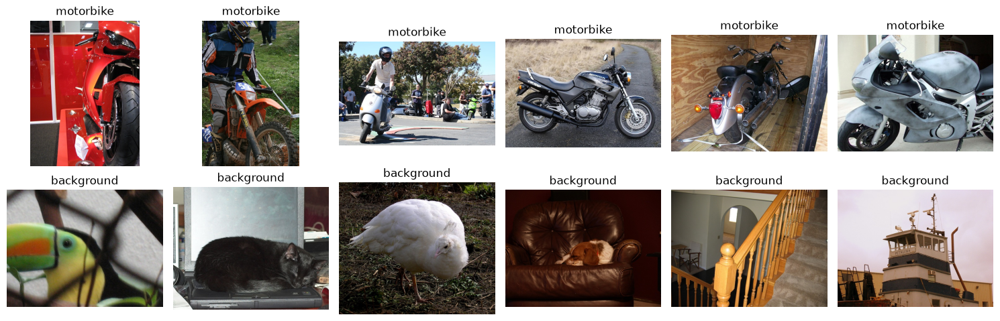

Training histograms shape: (911, 2048)
Validation histograms shape: (228, 2048)
Testing histograms shape: (1202, 2048)


In [2]:
encoding = "bovw_K512_C0"
#encoding = "vlad_K32_C80"
#encoding = "fv_K32_C80"
#encoding = "bovw_K256_C0"
#encoding = "bovw_K1024_C0"

category = "motorbike"
#category = "aeroplane"
#category = "person"

# Load training data
histograms, labels, names = loadEncodingSubset(category, encoding, subset="train")

# Load testing data (o subset "val" dos ficheiros é o nosso TESTE)
testHistograms, testLabels, testNames = loadEncodingSubset(category, encoding, subset="val")

################################################################################
# Create a validation split from the training data
################################################################################
trainHist, valHist, trainLabels, valLabels, trainNames, valNames = split_train_val(
    histograms, labels, names
)

################################################################################
# Throw away part of the training data (Stage G)
################################################################################
# trainHist, trainNames, trainLabels = get_subset(trainHist, trainNames, trainLabels, 0.1)
# trainHist, trainNames, trainLabels = get_subset(trainHist, trainNames, trainLabels, 0.5)

################################################################################
# Show some statistics about the dataset
################################################################################
print("Encoding : {}\nCategory: {}\nEncoding Size: {}".format(encoding, category, trainHist.shape[1]))
printDatasetStats(trainHist, trainNames, trainLabels, subset="train")
printDatasetStats(valHist, valNames, valLabels, subset="val")
printDatasetStats(testHistograms, testNames, testLabels, subset="test")

# Inspect representative images
show_examples(trainNames, trainLabels, category)

################################################################################
# Vary the image representation
################################################################################
# trainHist = remove_spatial_information(trainHist)
# valHist = remove_spatial_information(valHist)
# testHistograms = remove_spatial_information(testHistograms)

################################################################################
# Vary the classifier (Hellinger kernel) -> Stage F
################################################################################
# ** insert code here for the Hellinger kernel using  **
# ** the training histograms and testHistograms       **

# L2 normalize the histograms before running the linear SVM
trainHist = l2norm(trainHist)
valHist = l2norm(valHist)
testHistograms = l2norm(testHistograms)

print("Training histograms shape:", trainHist.shape)
print("Validation histograms shape:", valHist.shape)
print("Testing histograms shape:", testHistograms.shape)

## Stage A: vocabulário (K) e tiling vs histograma global



In [3]:
results = []

for enc in ["bovw_K256_C0", "bovw_K512_C0", "bovw_K1024_C0"]:
    if not os.path.exists(f"data/encodings/{enc}/{category}_train.npz"):
        print(f"{enc}: encodings em falta, a saltar (ver comandos acima).")
        continue

    hist, lab, nam = loadEncodingSubset(category, enc, subset="train")
    # Os ficheiros de todas as encodings têm as imagens pela mesma ordem, por isso
    # o split com a mesma seed dá exatamente as mesmas imagens de treino/validação.
    assert np.array_equal(nam, names), "ordem das imagens diferente entre encodings"
    x_tr, x_val, y_tr, y_val, _, _ = split_train_val(hist, lab, nam)

    for spatial in (True, False):
        xt = x_tr if spatial else remove_spatial_information(x_tr)
        xv = x_val if spatial else remove_spatial_information(x_val)

        ap, train_time = evaluate_ap(l2norm(xt), y_tr, l2norm(xv), y_val)
        results.append({
            "encoding": enc,
            "representação": "tiling 2x2" if spatial else "global",
            "dimensão": xt.shape[1],
            "AP validação": round(ap, 4),
            "treino SVM (s)": round(train_time, 2),
        })

pd.DataFrame(results)

,encoding,representação,dimensão,AP validação,treino SVM (s)
0,bovw_K256_C0,tiling 2x2,1024,0.4534,0.13
1,bovw_K256_C0,global,256,0.5030,0.03
2,bovw_K512_C0,tiling 2x2,2048,0.5191,0.27
3,bovw_K512_C0,global,512,0.6798,0.08
4,bovw_K1024_C0,tiling 2x2,4096,0.4973,0.49
5,bovw_K1024_C0,global,1024,0.5806,0.14


# Stage B: Training a classifier



Tempo de treino do SVM: 0.28 s


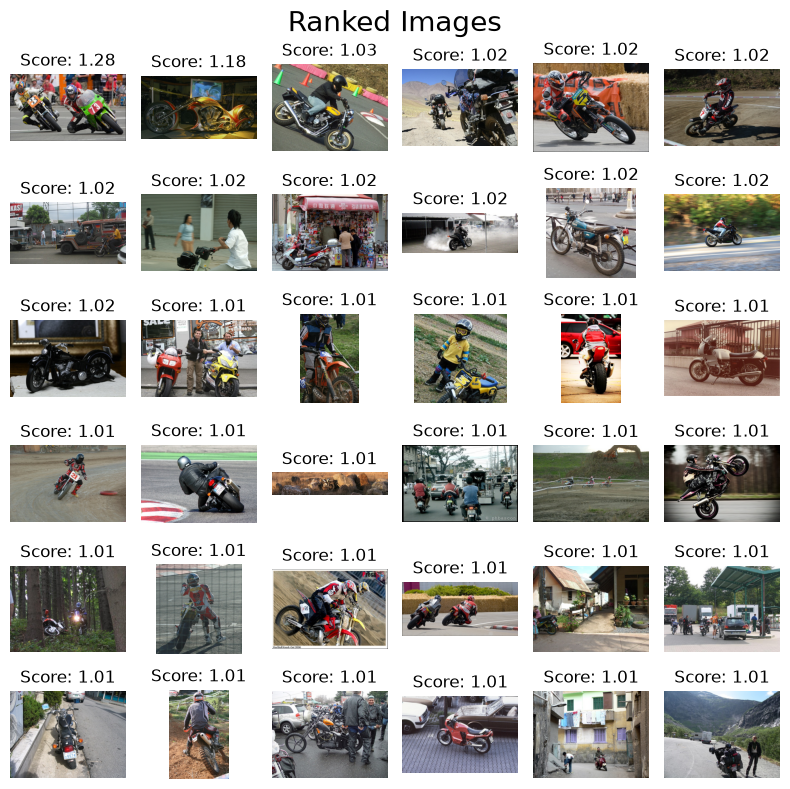

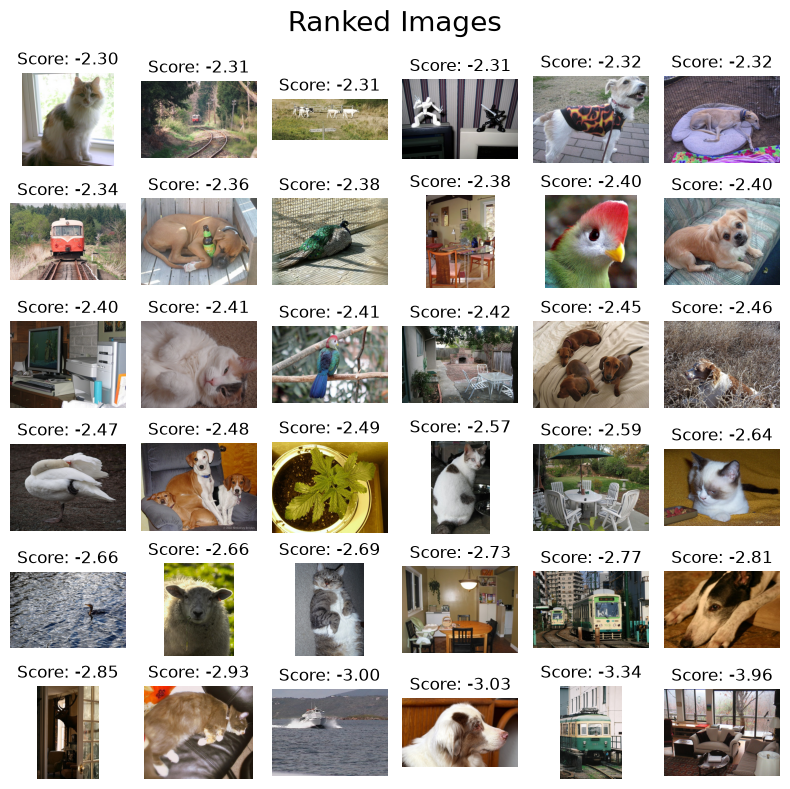

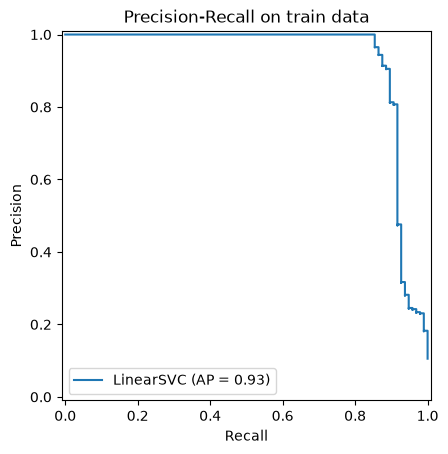

AP treino:    0.9329
AP validação: 0.5191


In [4]:
# Configure and train the linear SVM
start = time.perf_counter()
W, b = utils.train_svm(trainHist, trainLabels, C=10)
print(f"Tempo de treino do SVM: {time.perf_counter() - start:.2f} s")


scores = W @ trainHist.T + b

# topo do ranking
full_paths = [f"data/images/{name}.jpg" for name in trainNames]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8, 8))

# ... e fundo do ranking (os 36 scores mais baixos)
lowest = np.argsort(scores)[:36]
displayRankedImageList(scores[lowest], [full_paths[i] for i in lowest], uniform=False, figzize=(8, 8))

# Curva precision-recall 
_ = displayPrecisionRecallCurve(trainLabels, scores, title="Precision-Recall on train data")

# Comparar com a validação
valScores = W @ valHist.T + b
print(f"AP treino:    {average_precision_score(trainLabels, scores):.4f}")
print(f"AP validação: {average_precision_score(valLabels, valScores):.4f}")

## Stage B: palavras visuais relevantes



In [5]:
assert "bovw" in encoding, "only works for BOVW encoding"

# Imagem de treino com o score mais alto
top_idx = np.argmax(scores)
print("Imagem:", trainNames[top_idx], "| label:", trainLabels[top_idx], "| score:", round(scores[top_idx], 3))

W_per_word = W.reshape(4, -1).mean(axis=0)   # (2048,) -> (512,): média de cada palavra nos 4 tiles

encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
img = encoders.standarizeImage(f"data/images/{trainNames[top_idx]}.jpg")
rvwdisplay = RelevantVisualWordsDisplay(img, W_per_word, encoder)

import ipywidgets as widgets
@widgets.interact(rank=(0, len(rvwdisplay) - 1))
def display_relevant_visual_words(rank=0):
    rvwdisplay.plot(rank, figsize=(12, 8))

Imagem: 005173 | label: 1 | score: 1.276
Number of keypoints: 31537 Descriptor dimension: 128


interactive(children=(IntSlider(value=0, description='rank', max=511), Output()), _dom_classes=('widget-intera…

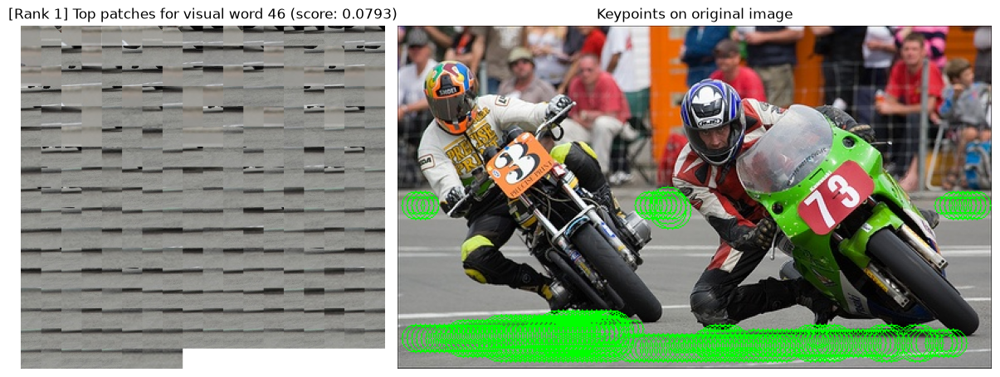

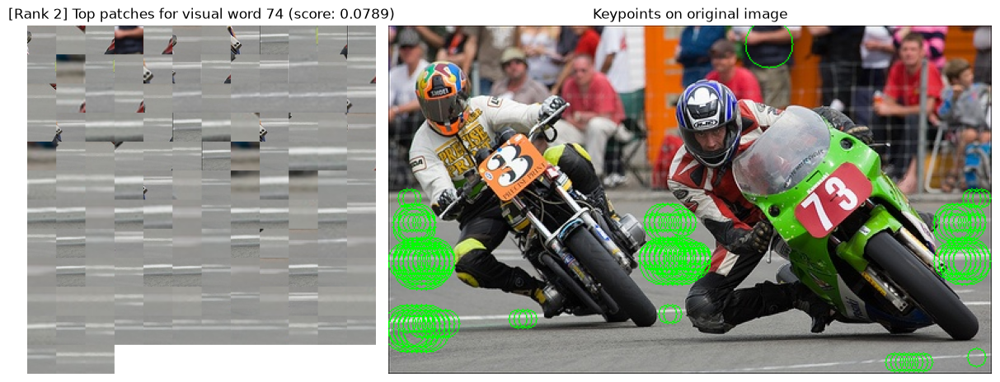

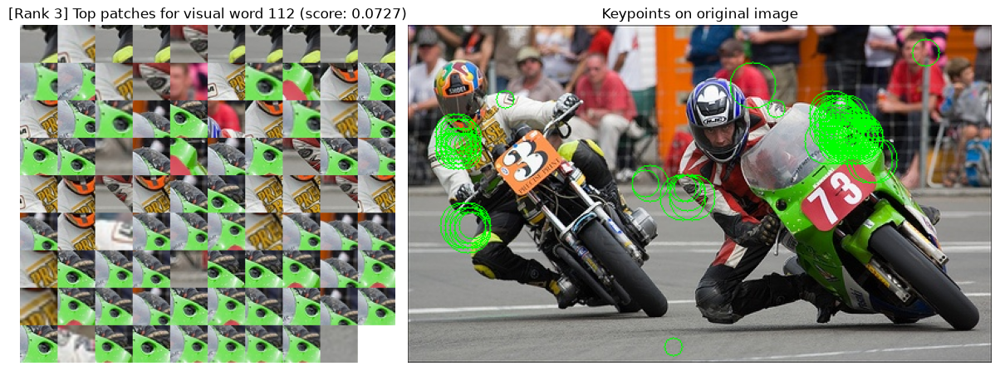

In [6]:

show_original = plt.show
plt.show = lambda: None

for rank in range(3):  # as 3 palavras visuais com mais peso
    rvwdisplay.plot(rank, figsize=(12, 8))
    plt.savefig(f"palavras_relevantes_rank{rank + 1}.png", dpi=150, bbox_inches="tight")
    show_original()

plt.show = show_original

# Stage C: Classify the test images and assess the performance



Inferência: 0.0021 ms por imagem (sem extração de features)
Correctly retrieved in the top 36: 30


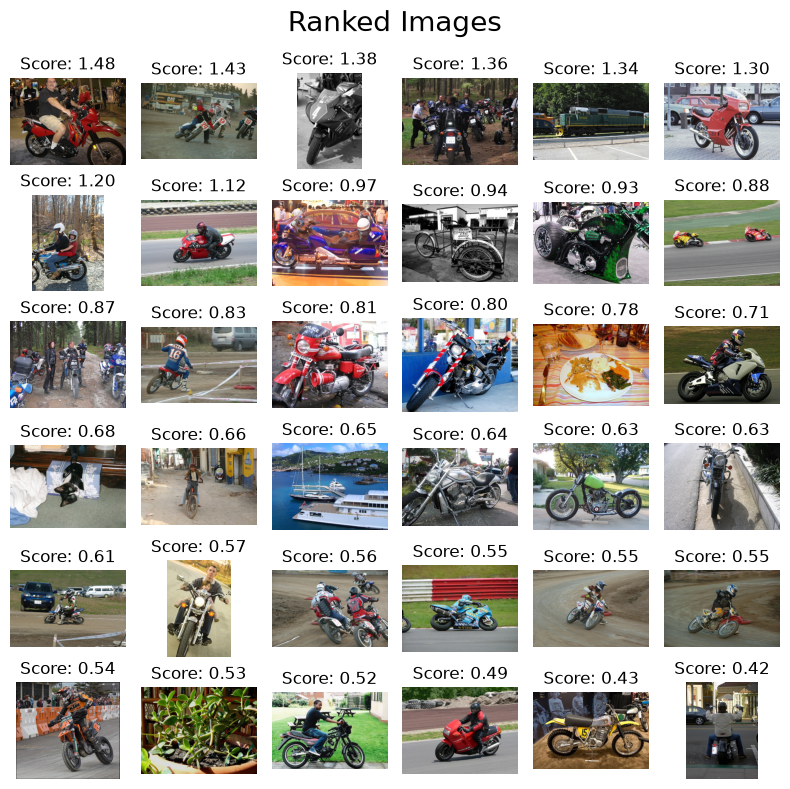

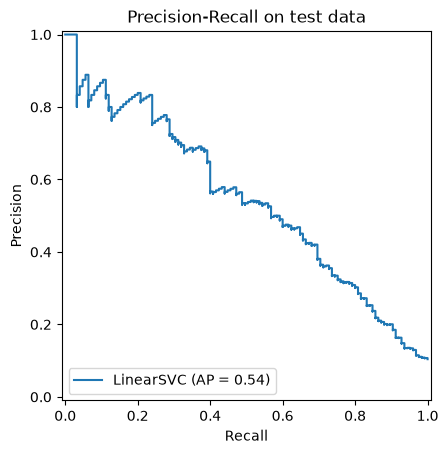

Average Precision (AP) on test data: 0.5440


In [7]:
# Final model: train + validation
finalHist = np.concatenate([trainHist, valHist])
finalLabels = np.concatenate([trainLabels, valLabels])
W, b = utils.train_svm(finalHist, finalLabels, C=10)

# Testar o Linear SVM
start = time.perf_counter()
testScores = W @ testHistograms.T + b
inference_time = time.perf_counter() - start
print(f"Inferência: {inference_time * 1000 / len(testLabels):.4f} ms por imagem (sem extração de features)")

# Print Resultados
perm = np.argsort(testScores)[::-1]
print('Correctly retrieved in the top 36: {:d}'.format(sum(testLabels[perm[:36]] > 0)))


full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8, 8))

# Visualizar a curva precision-recall
*_, ap = displayPrecisionRecallCurve(testLabels, testScores, title="Precision-Recall on test data")
print(f"Average Precision (AP) on test data: {ap:.4f}")

## Stage C: o bias não muda o ranking



In [8]:
ap_with_bias = average_precision_score(testLabels, W @ testHistograms.T + b)
ap_without_bias = average_precision_score(testLabels, W @ testHistograms.T)
print(f"AP com bias:  {ap_with_bias:.6f}")
print(f"AP sem bias:  {ap_without_bias:.6f}")
print("Mesmo ranking:", np.array_equal(np.argsort(W @ testHistograms.T + b), np.argsort(W @ testHistograms.T)))

AP com bias:  0.543958
AP sem bias:  0.543958
Mesmo ranking: True


# Parte 1 (continuação): Stages D–G, e Parte 2: Stages H–I



In [9]:
import platform

import sklearn
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split

from src.visualization import displayPrecisionRecallCurve

C = 10
CANDIDATE_CATEGORIES = ["aeroplane", "motorbike", "person", "horse", "car"]

# O enunciado pede para registar hardware e versões
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())

Python: 3.11.17 | NumPy: 2.4.6 | scikit-learn: 1.9.1
CPU: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | núcleos: 16


In [10]:
def category_exists(category, encoding="bovw_K512_C0"):
    return os.path.exists(f"data/encodings/{encoding}/{category}_train.npz")


def load_data(category, encoding, val_fraction=0.2, seed=SEED):
    x, y, names = loadEncodingSubset(category, encoding, subset="train")
    x_test, y_test, names_test = loadEncodingSubset(category, encoding, subset="val")

    # float32 chega para o SVM e gasta metade da memória do float64 (importante no FV, ~20 000 dimensões)
    x, x_test = x.astype(np.float32), x_test.astype(np.float32)

    x_train, x_val, y_train, y_val, names_train, names_val = train_test_split(
        x, y, names, test_size=val_fraction, stratify=y, random_state=seed)

    return {"x_train": x_train, "y_train": y_train, "names_train": names_train,
            "x_val": x_val, "y_val": y_val, "names_val": names_val,
            "x_test": x_test, "y_test": y_test, "names_test": names_test}





def signed_sqrt(x):
    # Para o BoVW (valores >= 0) é igual a np.sqrt. O sinal só importa no VLAD e no FV.
    return np.sign(x) * np.sqrt(np.abs(x))


def intra_normalize(x, block_size):
    # VLAD: normaliza com L2 cada bloco de resíduos (um bloco = um centro, block_size = D)
    blocks = x.reshape(x.shape[0], -1, block_size)
    blocks = blocks / (np.linalg.norm(blocks, axis=2, keepdims=True) + 1e-10)
    return blocks.reshape(x.shape[0], -1)


def preprocess(x, steps, block_size=None):
    for step in steps:
        if step == "global":
            x = remove_spatial_information(x)
        elif step == "l1":
            x = l1norm(x)
        elif step == "l2":
            x = l2norm(x)
        elif step == "sqrt":
            x = signed_sqrt(x)
        elif step == "intra":
            x = intra_normalize(x, block_size)
        else:
            raise ValueError(f"Passo desconhecido: {step}")
    return x


# --- Treino e avaliação -----------------------------------------------------------

def validation_ap(data, steps, C=C, block_size=None):
    # Treina no treino e avalia na validação -> (AP, tempo de treino em s, dimensão)
    x_train = preprocess(data["x_train"], steps, block_size)
    x_val = preprocess(data["x_val"], steps, block_size)

    start = time.perf_counter()
    W, b = utils.train_svm(x_train, data["y_train"], C=C)
    train_time = time.perf_counter() - start

    ap = average_precision_score(data["y_val"], W @ x_val.T + b)
    return ap, train_time, x_train.shape[1]


def test_ap(data, steps, C=C, block_size=None):
    # Modelo final: treina com treino + validação e avalia uma única vez no teste
    x_final = preprocess(np.concatenate([data["x_train"], data["x_val"]]), steps, block_size)
    y_final = np.concatenate([data["y_train"], data["y_val"]])
    x_test = preprocess(data["x_test"], steps, block_size)

    start = time.perf_counter()
    W, b = utils.train_svm(x_final, y_final, C=C)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    scores = W @ x_test.T + b
    inference_ms = (time.perf_counter() - start) * 1000 / len(x_test)

    ap = average_precision_score(data["y_test"], scores)
    return {"ap": ap, "scores": scores, "train_time": train_time, "inference_ms": inference_ms}


categories = [c for c in CANDIDATE_CATEGORIES if category_exists(c)]
print("Categorias disponíveis:", categories)

Categorias disponíveis: ['aeroplane', 'motorbike', 'person']


# Stage D: Other categories



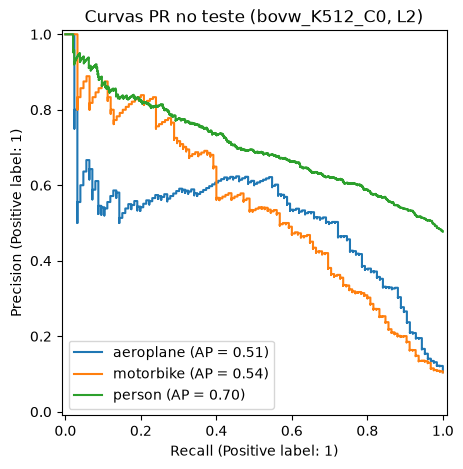

mAP teste: 0.5865


,categoria,positivos treino+val,positivos teste,AP aleatório,AP validação,AP teste
0,aeroplane,112,126,0.105,0.6236,0.5107
1,motorbike,120,125,0.104,0.5191,0.5440
2,person,1025,983,0.477,0.7123,0.7047


In [11]:
encoding = "bovw_K512_C0"
steps = ["l2"]

rows = []
fig, ax = plt.subplots(figsize=(6, 5))

for category in categories:
    data = load_data(category, encoding)
    ap_val, _, _ = validation_ap(data, steps)
    result = test_ap(data, steps)

    rows.append({
        "categoria": category,
        "positivos treino+val": int(np.sum(np.concatenate([data["y_train"], data["y_val"]]) > 0)),
        "positivos teste": int(np.sum(data["y_test"] > 0)),
        "AP aleatório": round(np.mean(data["y_test"] > 0), 3),
        "AP validação": round(ap_val, 4),
        "AP teste": round(result["ap"], 4),
    })
    PrecisionRecallDisplay.from_predictions(data["y_test"], result["scores"], ax=ax, name=category)

ax.set_title(f"Curvas PR no teste ({encoding}, L2)")
plt.show()

stage_d = pd.DataFrame(rows)
print(f"mAP teste: {stage_d['AP teste'].mean():.4f}")
stage_d

# Stage E: Normalization and spatial information



In [12]:
normalizations = {"nenhuma": [], "L1": ["l1"], "L2": ["l2"]}

rows = []
for category in categories:
    data = load_data(category, "bovw_K512_C0")
    for representation, spatial_steps in [("tiling 2x2", []), ("global", ["global"])]:
        for norm_name, norm_steps in normalizations.items():
            ap, train_time, dim = validation_ap(data, spatial_steps + norm_steps)
            rows.append({"categoria": category, "representação": representation,
                         "normalização": norm_name, "dimensão": dim,
                         "AP validação": round(ap, 4), "treino (s)": round(train_time, 2)})

stage_e = pd.DataFrame(rows)
stage_e.pivot_table(index=["categoria", "representação"], columns="normalização", values="AP validação")

normalização                 L1      L2  nenhuma
categoria representação                         
aeroplane global         0.7089  0.5363   0.6098
          tiling 2x2     0.7008  0.6236   0.7052
motorbike global         0.5134  0.6798   0.5279
          tiling 2x2     0.5442  0.5191   0.4983
person    global         0.6605  0.7406   0.6696
          tiling 2x2     0.5920  0.7123   0.6662

## Stage E: evidência para as perguntas sobre auto-semelhança



In [13]:
def self_similarity_report(x):
    kernel = x @ x.T
    self_sim = np.diag(kernel).copy()

    others = kernel.copy()
    np.fill_diagonal(others, -np.inf)              # ignora a própria imagem
    beaten = others.max(axis=1) > self_sim + 1e-6   # 1e-6: tolerância para erros de arredondamento

    return {"K(h,h) mín": self_sim.min(), "K(h,h) máx": self_sim.max(),
            "% imagens com K(h,h') > K(h,h)": round(100 * beaten.mean(), 1)}


data = load_data("motorbike", "bovw_K512_C0")

reports = {}
for name, steps in normalizations.items():
    reports[name] = self_similarity_report(preprocess(data["x_val"], steps))

pd.DataFrame(reports).T

,"K(h,h) mín","K(h,h) máx","% imagens com K(h,h') > K(h,h)"
nenhuma,1.027445e+06,2.024455e+08,80.3
L1,1.122018e-03,1.787166e-01,79.4
L2,9.999968e-01,1.000004e+00,0.0


# Stage F: Hellinger feature map



In [14]:
hellinger_variants = {
    "Linear + L2 (referência)": ["l2"],
    "√ sem normalização": ["sqrt"],
    "L1 → √ (Hellinger clássico)": ["l1", "sqrt"],
    "√ → L2": ["sqrt", "l2"],
    "L2 → √": ["l2", "sqrt"],
    "√ → L1": ["sqrt", "l1"],
}

rows = []
for category in categories:
    data = load_data(category, "bovw_K512_C0")
    for name, steps in hellinger_variants.items():
        ap, _, _ = validation_ap(data, steps)
        rows.append({"categoria": category, "variante": name, "AP validação": round(ap, 4)})

stage_f = pd.DataFrame(rows)
stage_f.pivot_table(index="variante", columns="categoria", values="AP validação", sort=False)

categoria,aeroplane,motorbike,person
variante,,,
Linear + L2 (referência),0.6236,0.5191,0.7123
√ sem normalização,0.7424,0.6406,0.7510
L1 → √ (Hellinger clássico),0.7654,0.6956,0.7569
√ → L2,0.7654,0.6956,0.7569
L2 → √,0.7168,0.6862,0.7257
√ → L1,0.5901,0.5689,0.6098


**Verificação numérica:** L1 → √ e √ → L2 devem dar **exatamente** o mesmo vetor,
porque ‖√h‖₂² = Σ hᵢ = ‖h‖₁ para h ≥ 0.

In [15]:
data = load_data("motorbike", "bovw_K512_C0")
l1_then_sqrt = preprocess(data["x_val"], ["l1", "sqrt"])
sqrt_then_l2 = preprocess(data["x_val"], ["sqrt", "l2"])
print("L1 → √ igual a √ → L2:", np.allclose(l1_then_sqrt, sqrt_then_l2, atol=1e-5))
print("Norma L2 após L1 → √ (deve ser 1):", np.round(np.linalg.norm(l1_then_sqrt, axis=1)[:5], 4))

L1 → √ igual a √ → L2: True
Norma L2 após L1 → √ (deve ser 1): [1. 1. 1. 1. 1.]


**Efeito de C**:

In [16]:
rows = []
for c_value in (0.1, 1, 10, 100):
    for name in ("Linear + L2 (referência)", "√ → L2"):
        ap, _, _ = validation_ap(data, hellinger_variants[name], C=c_value)
        rows.append({"C": c_value, "variante": name, "AP validação": round(ap, 4)})
pd.DataFrame(rows).pivot_table(index="C", columns="variante", values="AP validação")

variante,Linear + L2 (referência),√ → L2
C,,
0.1,0.4177,0.5370
1.0,0.5074,0.7038
10.0,0.5191,0.6956
100.0,0.5741,0.6705


**Teste final para motorbike:** a variante com maior AP **na validação** é escolhida automaticamente
e só depois é avaliada no teste.

Variante escolhida na validação: L1 → √ (Hellinger clássico)
Linear + L2 (referência)       AP teste = 0.5440
L1 → √ (Hellinger clássico)    AP teste = 0.6509


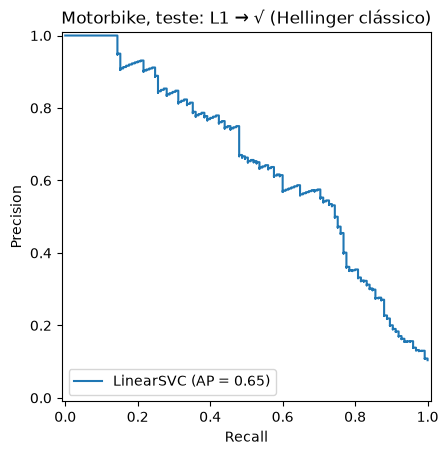

In [17]:
motorbike_val = stage_f[stage_f["categoria"] == "motorbike"]
best_variant = motorbike_val.loc[motorbike_val["AP validação"].idxmax(), "variante"]
print("Variante escolhida na validação:", best_variant)

data = load_data("motorbike", "bovw_K512_C0")
for name in ("Linear + L2 (referência)", best_variant):
    result = test_ap(data, hellinger_variants[name])
    print(f"{name:30s} AP teste = {result['ap']:.4f}")

*_, ap = displayPrecisionRecallCurve(data["y_test"], result["scores"],
                                     title=f"Motorbike, teste: {best_variant}")

# Stage G: Vary the number of training images



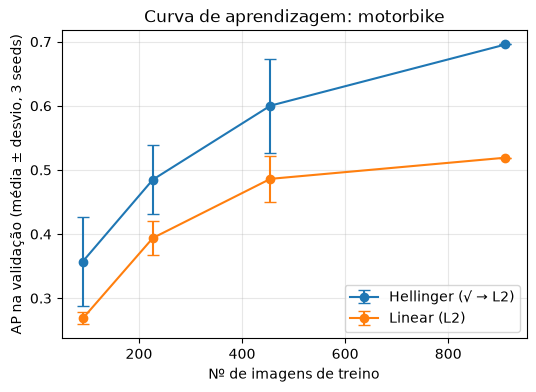

n_imagens  n_positivos  AP_média  AP_desvio
kernel             fração                                             
Hellinger (√ → L2) 0.10           91           10    0.3572     0.0698
                   0.25          227           24    0.4849     0.0534
                   0.50          455           48    0.6002     0.0732
                   1.00          911           96    0.6956     0.0000
Linear (L2)        0.10           91           10    0.2684     0.0094
                   0.25          227           24    0.3939     0.0271
                   0.50          455           48    0.4861     0.0359
                   1.00          911           96    0.5191     0.0000

In [18]:
def subsample(x, y, fraction, seed):
    if fraction >= 1:
        return x, y
    x_sub, _, y_sub, _ = train_test_split(x, y, train_size=fraction, stratify=y, random_state=seed)
    return x_sub, y_sub


category = "motorbike"
fractions = [0.10, 0.25, 0.50, 1.00]
seeds = [0, 1, 2]
kernels = {"Linear (L2)": ["l2"], "Hellinger (√ → L2)": ["sqrt", "l2"]}

data = load_data(category, "bovw_K512_C0")
rows = []
for kernel_name, steps in kernels.items():
    # A normalização é por imagem, por isso pode ser feita uma vez antes de subamostrar
    x_train = preprocess(data["x_train"], steps)
    x_val = preprocess(data["x_val"], steps)

    for fraction in fractions:
        for seed in seeds:
            x_sub, y_sub = subsample(x_train, data["y_train"], fraction, seed)
            W, b = utils.train_svm(x_sub, y_sub, C=C)
            ap = average_precision_score(data["y_val"], W @ x_val.T + b)
            rows.append({"kernel": kernel_name, "fração": fraction, "seed": seed,
                         "nº imagens treino": len(y_sub), "nº positivos": int(np.sum(y_sub > 0)), "AP validação": ap})

stage_g = pd.DataFrame(rows)
groups = stage_g.groupby(["kernel", "fração"])
summary_g = pd.DataFrame({
    "n_imagens": groups["nº imagens treino"].first(),
    "n_positivos": groups["nº positivos"].first(),
    "AP_média": groups["AP validação"].mean(),
    "AP_desvio": groups["AP validação"].std(),
}).round(4)

fig, ax = plt.subplots(figsize=(6, 4))
for kernel_name, group in summary_g.groupby(level="kernel"):
    ax.errorbar(group["n_imagens"], group["AP_média"], yerr=group["AP_desvio"],
                marker="o", capsize=4, label=kernel_name)
ax.set_xlabel("Nº de imagens de treino")
ax.set_ylabel("AP na validação (média ± desvio, 3 seeds)")
ax.set_title(f"Curva de aprendizagem: {category}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

summary_g

# Parte 2: VLAD e Fisher Vectors



In [19]:
def evaluate_encoding(encoding, variants, block_size=None):
    val_rows, test_rows = [], []

    for category in categories:
        data = load_data(category, encoding)
        for name, steps in variants.items():
            ap, train_time, dim = validation_ap(data, steps, block_size=block_size)
            val_rows.append({"categoria": category, "variante": name, "dimensão": dim,
                             "AP validação": ap, "treino (s)": train_time})

    val_table = pd.DataFrame(val_rows)
    mean_val = val_table.groupby("variante", sort=False)["AP validação"].mean()
    best = mean_val.idxmax()
    print(f"{encoding}: variante escolhida na validação = {best} (AP médio {mean_val[best]:.4f})")

    for category in categories:
        data = load_data(category, encoding)
        result = test_ap(data, variants[best], block_size=block_size)
        test_rows.append({"categoria": category, "AP teste": result["ap"],
                          "treino final (s)": result["train_time"],
                          "inferência (ms/img)": result["inference_ms"]})

    val_pivot = val_table.pivot_table(index="variante", columns="categoria",
                                      values="AP validação", sort=False).round(4)
    return val_pivot, pd.DataFrame(test_rows).round(4), best, val_table["dimensão"].iloc[0]


summary = {}   # resultados finais de cada encoding, para a tabela comparativa

## Referência: BoVW com o mesmo procedimento

Corre-se o BoVW pela mesma função, para a comparação final usar exatamente o mesmo protocolo.

In [20]:
bovw_variants = {"L2": ["l2"], "Hellinger (√ → L2)": ["sqrt", "l2"]}
val_pivot, test_table, best, dim = evaluate_encoding("bovw_K512_C0", bovw_variants)
summary["bovw_K512_C0"] = {"variante": best, "dimensão": dim, "test": test_table}
display(val_pivot)
test_table

bovw_K512_C0: variante escolhida na validação = Hellinger (√ → L2) (AP médio 0.7393)


categoria,aeroplane,motorbike,person
variante,,,
L2,0.6236,0.5191,0.7123
Hellinger (√ → L2),0.7654,0.6956,0.7569


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7414,0.1995,0.0298
1,motorbike,0.6509,0.2844,0.0239
2,person,0.7812,0.7633,0.0332


# Stage H: VLAD



In [21]:
vlad_encoding = "vlad_K32_C80"
vlad_words = np.load(f"data/encoders/{vlad_encoding}.npz")["words"]   # shape (K, D)
K, D = vlad_words.shape
print(f"VLAD: K = {K}, D = {D}, dimensão nominal K×D = {K * D} por tile, {4 * K * D} com 4 tiles")

vlad_variants = {
    "nenhuma": [],
    "L2": ["l2"],
    "√ → L2": ["sqrt", "l2"],
    "intra → L2": ["intra", "l2"],
    "√ → intra → L2": ["sqrt", "intra", "l2"],
}
val_pivot, test_table, best, dim = evaluate_encoding(vlad_encoding, vlad_variants, block_size=D)
summary[vlad_encoding] = {"variante": best, "dimensão": dim, "test": test_table}
display(val_pivot)
test_table

VLAD: K = 32, D = 80, dimensão nominal K×D = 2560 por tile, 10240 com 4 tiles
vlad_K32_C80: variante escolhida na validação = √ → L2 (AP médio 0.8125)


categoria,aeroplane,motorbike,person
variante,,,
nenhuma,0.7917,0.6658,0.7786
L2,0.7916,0.6623,0.7894
√ → L2,0.7994,0.8154,0.8229
intra → L2,0.7862,0.7715,0.7960
√ → intra → L2,0.7660,0.7962,0.8190


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7528,0.7693,0.1401
1,motorbike,0.7490,1.3382,0.1377
2,person,0.7817,4.6937,0.1703


# Stage I: Fisher Vector



In [22]:
fv_encoding = "fv_K32_C80"
fv_cfg = np.load(f"data/encoders/{fv_encoding}.npz")
K_fv, D_fv = fv_cfg["means"].shape
print(f"FV: K = {K_fv}, D = {D_fv}, dimensão nominal 2·K·D = {2 * K_fv * D_fv} por tile")

fv_variants = {
    "nenhuma": [],
    "L2": ["l2"],
    "√ → L2 (Improved FV)": ["sqrt", "l2"],
}
val_pivot, test_table, best, dim = evaluate_encoding(fv_encoding, fv_variants)
summary[fv_encoding] = {"variante": best, "dimensão": dim, "test": test_table}
print(f"Dimensão real: {dim} ({dim // 4} por tile)")
display(val_pivot)
test_table

FV: K = 32, D = 80, dimensão nominal 2·K·D = 5120 por tile
fv_K32_C80: variante escolhida na validação = √ → L2 (Improved FV) (AP médio 0.8005)
Dimensão real: 20608 (5152 por tile)


categoria,aeroplane,motorbike,person
variante,,,
nenhuma,0.7580,0.7656,0.7881
L2,0.7445,0.8049,0.7952
√ → L2 (Improved FV),0.7469,0.8131,0.8415


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7730,2.6984,0.0953
1,motorbike,0.8061,3.1878,0.0683
2,person,0.8189,9.4944,0.0902


# Comparação BoVW vs VLAD vs FV



In [23]:
from src.features import computeFeatures

sample_names = load_data("motorbike", "bovw_K512_C0")["names_test"][:10]
sample_paths = [f"data/images/{name}.jpg" for name in sample_names]

start = time.perf_counter()
features = [computeFeatures(path) for path in sample_paths]
sift_ms = (time.perf_counter() - start) * 1000 / len(features)
print(f"SIFT denso: {sift_ms:.0f} ms por imagem")

encoding_ms = {}
for encoding in summary:
    encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
    start = time.perf_counter()
    for keypoints, descriptors, image_size in features:
        encoder.encode_tiling(keypoints, descriptors, image_size)
    encoding_ms[encoding] = (time.perf_counter() - start) * 1000 / len(features)
    print(f"{encoding:15s} codificação: {encoding_ms[encoding]:.0f} ms por imagem")

SIFT denso: 221 ms por imagem
bovw_K512_C0    codificação: 159 ms por imagem
vlad_K32_C80    codificação: 96 ms por imagem
fv_K32_C80      codificação: 179 ms por imagem


In [24]:
def disk_size_per_image_kb(encoding):
    folder = f"data/encodings/{encoding}"
    total_bytes, total_images = 0, 0
    for file_name in os.listdir(folder):
        path = os.path.join(folder, file_name)
        total_bytes += os.path.getsize(path)
        total_images += len(np.load(path)["file_names"])
    return total_bytes / total_images / 1024


rows = []
for encoding, result in summary.items():
    test_table = result["test"]
    row = {"encoding": encoding, "variante (validação)": result["variante"], "dimensão": result["dimensão"]}
    for _, r in test_table.iterrows():
        row[f"AP {r['categoria']}"] = r["AP teste"]
    row["mAP teste"] = round(test_table["AP teste"].mean(), 4)
    row["treino SVM médio (s)"] = round(test_table["treino final (s)"].mean(), 2)
    row["inferência (ms/img)"] = round(test_table["inferência (ms/img)"].mean(), 4)
    row["codificação (ms/img)"] = round(encoding_ms.get(encoding, np.nan), 1)
    row["vetor float32 (KB)"] = round(result["dimensão"] * 4 / 1024, 1)
    row["disco .npz (KB/img)"] = round(disk_size_per_image_kb(encoding), 1)
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison

,encoding,variante (validação),dimensão,AP aeroplane,AP motorbike,AP person,mAP teste,treino SVM médio (s),inferência (ms/img),codificação (ms/img),vetor float32 (KB),disco .npz (KB/img)
0,bovw_K512_C0,Hellinger (√ → L2),2048,0.7414,0.6509,0.7812,0.7245,0.42,0.0290,159.3,8.0,2.2
1,vlad_K32_C80,√ → L2,10240,0.7528,0.7490,0.7817,0.7612,2.27,0.1494,95.9,40.0,36.5
2,fv_K32_C80,√ → L2 (Improved FV),20608,0.7730,0.8061,0.8189,0.7993,5.13,0.0846,178.6,80.5,153.6


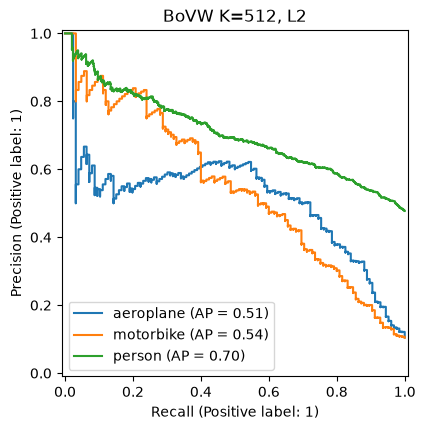

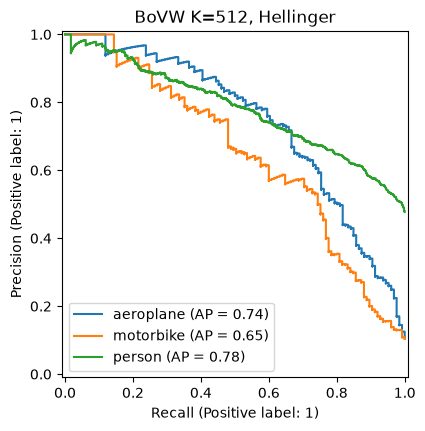

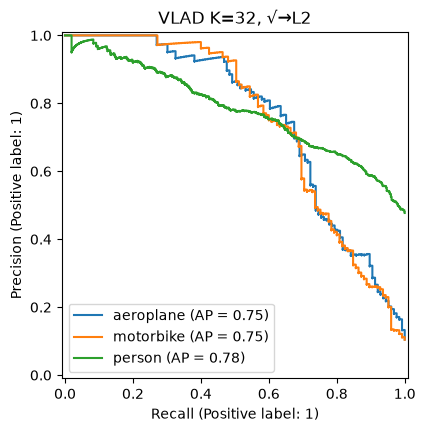

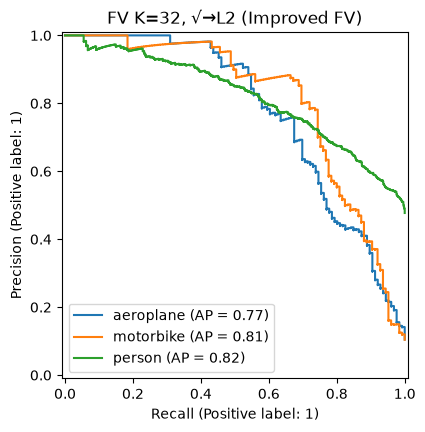

BoVW + L2


,categoria,AP teste,P@5,R@5,P@10,R@10,P@20,R@20,P@36,R@36,precisão (f>0),recall (f>0),VP,FP,FN,VN
0,aeroplane,0.5107,0.8,0.032,0.6,0.048,0.55,0.087,0.500,0.143,0.588,0.079,10,7,116,1070
1,motorbike,0.5440,0.8,0.032,0.8,0.064,0.80,0.128,0.833,0.240,0.641,0.400,50,28,75,1049
2,person,0.7047,1.0,0.005,1.0,0.010,1.00,0.020,0.944,0.035,0.671,0.583,573,281,410,796


BoVW + Hellinger


,categoria,AP teste,P@5,R@5,P@10,R@10,P@20,R@20,P@36,R@36,precisão (f>0),recall (f>0),VP,FP,FN,VN
0,aeroplane,0.7414,1.0,0.040,1.0,0.079,0.95,0.151,0.944,0.270,0.805,0.524,66,16,60,1061
1,motorbike,0.6509,1.0,0.040,1.0,0.080,0.95,0.152,0.889,0.256,0.732,0.480,60,22,65,1055
2,person,0.7812,1.0,0.005,1.0,0.010,0.95,0.019,0.972,0.036,0.702,0.687,675,286,308,791


VLAD


,categoria,AP teste,P@5,R@5,P@10,R@10,P@20,R@20,P@36,R@36,precisão (f>0),recall (f>0),VP,FP,FN,VN
0,aeroplane,0.7528,1.0,0.040,1.0,0.079,1.00,0.159,0.972,0.278,0.884,0.484,61,8,65,1069
1,motorbike,0.7490,1.0,0.040,1.0,0.080,1.00,0.160,0.972,0.280,0.848,0.536,67,12,58,1065
2,person,0.7817,1.0,0.005,1.0,0.010,0.95,0.019,0.972,0.036,0.693,0.695,683,302,300,775


FV


,categoria,AP teste,P@5,R@5,P@10,R@10,P@20,R@20,P@36,R@36,precisão (f>0),recall (f>0),VP,FP,FN,VN
0,aeroplane,0.7730,1.0,0.040,1.0,0.079,1.0,0.159,1.000,0.286,0.883,0.540,68,9,58,1068
1,motorbike,0.8061,1.0,0.040,1.0,0.080,1.0,0.160,0.972,0.280,0.875,0.504,63,9,62,1068
2,person,0.8189,1.0,0.005,1.0,0.010,1.0,0.020,1.000,0.037,0.746,0.709,697,237,286,840


In [25]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score


def precision_recall_at_k(y_true, scores, k):
    top_k = np.argsort(scores)[::-1][:k]          # as k imagens com score mais alto
    hits = np.sum(y_true[top_k] > 0)              # quantas dessas são positivas
    return hits / k, hits / np.sum(y_true > 0)    # P@k, R@k


def retrieval_report(encoding, steps, title, ks=(5, 10, 20, 36)):
    rows = []
    fig, ax = plt.subplots(figsize=(5, 4.5))

    for category in categories:
        data = load_data(category, encoding)
        result = test_ap(data, steps)             # mesmo protocolo: treino+val -> teste
        y, scores = data["y_test"], result["scores"]

        row = {"categoria": category, "AP teste": round(result["ap"], 4)}
        for k in ks:
            p, r = precision_recall_at_k(y, scores, k)
            row[f"P@{k}"] = round(p, 3)
            row[f"R@{k}"] = round(r, 3)

        # Classificação com o threshold natural do SVM: positivo se f(x) > 0
        y_pred = np.where(scores > 0, 1, -1)
        row["precisão (f>0)"] = round(precision_score(y, y_pred, pos_label=1, zero_division=0), 3)
        row["recall (f>0)"] = round(recall_score(y, y_pred, pos_label=1), 3)
        tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[-1, 1]).ravel()
        row.update({"VP": tp, "FP": fp, "FN": fn, "VN": tn})
        rows.append(row)

        PrecisionRecallDisplay.from_predictions(y, scores, ax=ax, name=category)

    ax.set_title(title)
    plt.savefig(f"pr_{encoding}_{'_'.join(steps)}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return pd.DataFrame(rows)


reports = {
    "BoVW + L2":        retrieval_report("bovw_K512_C0", ["l2"], "BoVW K=512, L2"),
    "BoVW + Hellinger": retrieval_report("bovw_K512_C0", ["sqrt", "l2"], "BoVW K=512, Hellinger"),
    "VLAD":             retrieval_report("vlad_K32_C80", ["sqrt", "l2"], "VLAD K=32, √→L2"),
    "FV":               retrieval_report("fv_K32_C80", ["sqrt", "l2"], "FV K=32, √→L2 (Improved FV)"),
}

for name, table in reports.items():
    print(name)
    display(table)

# Partes 3 e 5 — Vocabulários grandes com PCA e retrieval por imagem de consulta

Esta secção usa **os mesmos encodings e os mesmos conjuntos** dos notebooks anteriores:

- `train` dos ficheiros → treino (80%) + validação (20%, estratificada);
- `val` dos ficheiros → **teste**, usado uma única vez para reportar.

Normalização: em todas as experiências usa-se **√ → L2** (kernel de Hellinger),
porque foi a melhor variante nas Partes 1 e 2.



In [26]:
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score


def prepare(x, representation="global", use_sqrt=True):
    # representation: "global" (histograma da imagem inteira) ou "tiling" (4 tiles concatenados)
    if representation == "global":
        x = remove_spatial_information(x)
    if use_sqrt:
        x = signed_sqrt(x)
    return l2norm(x)


def encoding_exists(encoding, category="motorbike"):
    return os.path.exists(f"data/encodings/{encoding}/{category}_train.npz")

# Parte 3 — Vocabulário grande + PCA vs. vocabulário pequeno




In [27]:
def run_condition(category, encoding, pca_dim=0, representation="global", seed=SEED, final=False):
    data = load_data(category, encoding, seed=seed)

    if final:   # modelo final: treino + validação -> teste
        x_fit = np.concatenate([data["x_train"], data["x_val"]])
        y_fit = np.concatenate([data["y_train"], data["y_val"]])
        x_eval, y_eval = data["x_test"], data["y_test"]
    else:       # seleção: treino -> validação
        x_fit, y_fit = data["x_train"], data["y_train"]
        x_eval, y_eval = data["x_val"], data["y_val"]

    x_fit = prepare(x_fit, representation)
    x_eval = prepare(x_eval, representation)
    original_dim = x_fit.shape[1]

    # PCA ajustada só com os dados de treino desta corrida
    pca_time = 0.0
    if pca_dim:
        pca = PCA(n_components=pca_dim, random_state=SEED)
        start = time.perf_counter()
        pca.fit(x_fit)
        pca_time = time.perf_counter() - start
        x_fit = l2norm(pca.transform(x_fit))

    start = time.perf_counter()
    W, b = utils.train_svm(x_fit, y_fit, C=C)
    train_time = time.perf_counter() - start

    # Inferência = (projeção PCA, se houver) + produto interno com W
    start = time.perf_counter()
    if pca_dim:
        x_eval = l2norm(pca.transform(x_eval))
    scores = W @ x_eval.T + b
    inference_ms = (time.perf_counter() - start) * 1000 / len(x_eval)

    y_pred = np.where(scores > 0, 1, -1)
    return {"AP": average_precision_score(y_eval, scores),
            "accuracy": accuracy_score(y_eval, y_pred),
            "macro-F1": f1_score(y_eval, y_pred, average="macro"),
            "dim original": original_dim, "dim": x_fit.shape[1],
            "PCA fit (s)": pca_time, "treino SVM (s)": train_time,
            "inferência (ms/img)": inference_ms}

In [28]:
SEEDS = [42, 0, 1]

# (nome, encoding, representação, dimensão PCA (0 = sem PCA), família para o gráfico)
conditions = [
    ("A: K=256",            "bovw_K256_C0",  "global", 0,   "BoVW sem PCA"),
    ("B: K=512",            "bovw_K512_C0",  "global", 0,   "BoVW sem PCA"),
    ("B: K=1024",           "bovw_K1024_C0", "global", 0,   "BoVW K=1024 + PCA"),
    ("C: K=1024 + PCA 512", "bovw_K1024_C0", "global", 512, "BoVW K=1024 + PCA"),
    ("C: K=1024 + PCA 256", "bovw_K1024_C0", "global", 256, "BoVW K=1024 + PCA"),
    ("C: K=1024 + PCA 128", "bovw_K1024_C0", "global", 128, "BoVW K=1024 + PCA"),
    ("C: K=1024 + PCA 64",  "bovw_K1024_C0", "global", 64,  "BoVW K=1024 + PCA"),
    ("C: K=1024 + PCA 32",  "bovw_K1024_C0", "global", 32,  "BoVW K=1024 + PCA"),
    ("D: K=128",            "bovw_K128_C0",  "global", 0,   "BoVW sem PCA"),
    ("VLAD",                "vlad_K32_C80",  "tiling", 0,   "VLAD + PCA"),
    ("VLAD + PCA 256",      "vlad_K32_C80",  "tiling", 256, "VLAD + PCA"),
    ("VLAD + PCA 128",      "vlad_K32_C80",  "tiling", 128, "VLAD + PCA"),
    ("FV",                  "fv_K32_C80",    "tiling", 0,   "FV + PCA"),
    ("FV + PCA 256",        "fv_K32_C80",    "tiling", 256, "FV + PCA"),
    ("FV + PCA 128",        "fv_K32_C80",    "tiling", 128, "FV + PCA"),
]

# Saltam-se as condições cujos encodings não existem (por exemplo K=128)
available = []
for condition in conditions:
    if encoding_exists(condition[1]):
        available.append(condition)
    else:
        print(f"{condition[0]}: encodings {condition[1]} em falta, a saltar.")

rows = []
for name, encoding, representation, pca_dim, family in available:
    for category in categories:
        for seed in SEEDS:
            r = run_condition(category, encoding, pca_dim, representation, seed=seed)
            rows.append({"condição": name, "família": family, "categoria": category, "seed": seed,
                         "dim": r["dim"], "AP validação": r["AP"]})

val3 = pd.DataFrame(rows)

mean = val3.pivot_table(index="condição", columns="categoria", values="AP validação", aggfunc="mean", sort=False)
std = val3.pivot_table(index="condição", columns="categoria", values="AP validação", aggfunc="std", sort=False)

val_table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
val_table.insert(0, "dim", val3.groupby("condição", sort=False)["dim"].first())
val_table["mAP validação"] = mean.mean(axis=1).round(4)
val_table

D: K=128: encodings bovw_K128_C0 em falta, a saltar.


categoria,dim,aeroplane,motorbike,person,mAP validação
condição,,,,,
A: K=256,256,0.736 ± 0.079,0.584 ± 0.072,0.771 ± 0.01,0.6967
B: K=512,512,0.716 ± 0.083,0.634 ± 0.056,0.774 ± 0.007,0.7080
B: K=1024,1024,0.778 ± 0.084,0.674 ± 0.021,0.814 ± 0.009,0.7552
C: K=1024 + PCA 512,512,0.746 ± 0.078,0.651 ± 0.079,0.811 ± 0.011,0.7362
C: K=1024 + PCA 256,256,0.731 ± 0.087,0.625 ± 0.072,0.819 ± 0.01,0.7248
C: K=1024 + PCA 128,128,0.761 ± 0.049,0.589 ± 0.056,0.807 ± 0.009,0.7191
C: K=1024 + PCA 64,64,0.744 ± 0.059,0.549 ± 0.044,0.788 ± 0.01,0.6937
C: K=1024 + PCA 32,32,0.696 ± 0.083,0.47 ± 0.027,0.779 ± 0.009,0.6485
VLAD,10240,0.808 ± 0.049,0.729 ± 0.075,0.843 ± 0.019,0.7935


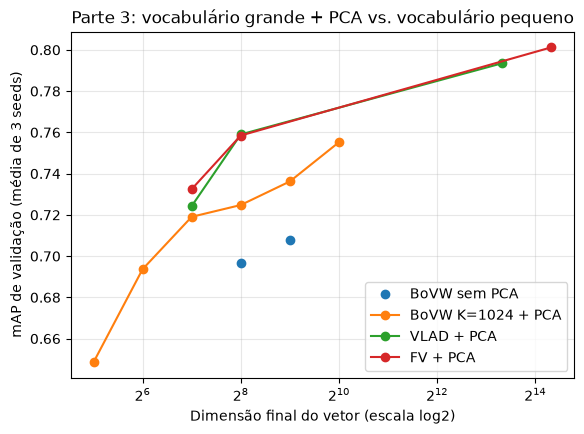

In [29]:
groups = val3.groupby(["condição", "família"], sort=False)
curve = pd.DataFrame({"dim": groups["dim"].first(), "mAP": groups["AP validação"].mean()}).reset_index()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for family, group in curve.groupby("família", sort=False):
    group = group.sort_values("dim")
    style = "o" if family == "BoVW sem PCA" else "o-"
    ax.plot(group["dim"], group["mAP"], style, label=family, markersize=6)

ax.set_xscale("log", base=2)
ax.set_xlabel("Dimensão final do vetor (escala log2)")
ax.set_ylabel("mAP de validação (média de 3 seeds)")
ax.set_title("Parte 3: vocabulário grande + PCA vs. vocabulário pequeno")
ax.grid(alpha=0.3)
ax.legend()
plt.savefig("parte3_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## Teste (uma vez, seed 42, retreino em treino + validação)


In [30]:
rows = []
for name, encoding, representation, pca_dim, family in available:
    for category in categories:
        row = {"condição": name, "categoria": category}
        row.update(run_condition(category, encoding, pca_dim, representation, final=True))
        rows.append(row)

test3 = pd.DataFrame(rows)

ap_test = test3.pivot_table(index="condição", columns="categoria", values="AP", sort=False).add_prefix("AP ")
groups = test3.groupby("condição", sort=False)
part3_test = pd.DataFrame({
    "dim_original": groups["dim original"].first(),
    "dim_final": groups["dim"].first(),
    "accuracy": groups["accuracy"].mean(),
    "macro_F1": groups["macro-F1"].mean(),
    "pca_fit_s": groups["PCA fit (s)"].mean(),
    "treino_svm_s": groups["treino SVM (s)"].mean(),
    "inferencia_ms": groups["inferência (ms/img)"].mean(),
})
part3_test["% removido"] = 100 * (1 - part3_test["dim_final"] / part3_test["dim_original"])
part3_test["vetor (KB/img)"] = part3_test["dim_final"] * 4 / 1024
part3_test = pd.concat([ap_test, part3_test], axis=1)
part3_test.insert(len(ap_test.columns), "mAP teste", ap_test.mean(axis=1))
part3_test.round(4)

,AP aeroplane,AP motorbike,AP person,mAP teste,dim_original,dim_final,accuracy,macro_F1,pca_fit_s,treino_svm_s,inferencia_ms,% removido,vetor (KB/img)
condição,,,,,,,,,,,,,
A: K=256,0.6704,0.4942,0.7433,0.6360,256,256,0.8394,0.6804,0.0000,0.0431,0.0016,0.0000,1.000
B: K=512,0.7015,0.5550,0.7652,0.6739,512,512,0.8524,0.7231,0.0000,0.0888,0.0040,0.0000,2.000
B: K=1024,0.7112,0.5868,0.7732,0.6904,1024,1024,0.8559,0.7424,0.0000,0.1968,0.0146,0.0000,4.000
C: K=1024 + PCA 512,0.6607,0.5812,0.7637,0.6685,1024,512,0.8463,0.7414,0.6990,0.0666,0.0073,50.0000,2.000
C: K=1024 + PCA 256,0.6309,0.5643,0.7686,0.6546,1024,256,0.8439,0.7410,0.2132,0.0263,0.0035,75.0000,1.000
C: K=1024 + PCA 128,0.6525,0.5518,0.7632,0.6559,1024,128,0.8450,0.7286,0.1815,0.0228,0.0032,87.5000,0.500
C: K=1024 + PCA 64,0.6577,0.5774,0.7674,0.6675,1024,64,0.8539,0.7407,0.1340,0.0122,0.0029,93.7500,0.250
C: K=1024 + PCA 32,0.6510,0.4544,0.7522,0.6192,1024,32,0.8448,0.7025,0.1234,0.0082,0.0023,96.8750,0.125
VLAD,0.7528,0.7490,0.7817,0.7611,10240,10240,0.8629,0.7720,0.0000,2.1838,0.1379,0.0000,40.000


## Tempos de codificação e de ajuste do dicionário

**Codificação** (por imagem): igual à secção da Parte 2, em 10 imagens de teste.

**Ajuste do dicionário e da PCA local**: o `train.py` não guarda estes tempos, por isso voltamos a
correr as funções dele (`sampleLocalFeatures`, `train_encoder`) **sem gravar nada**. Os encoders
em `data/encoders/` não são alterados. Usa os mesmos parâmetros por omissão do `train.py`
(150 imagens por classe, 400 descritores por imagem, seed 42).



In [31]:
from src.features import computeFeatures

encodings_to_time = sorted({encoding for _, encoding, _, _, _ in available})

sample_names = loadEncodingSubset("motorbike", "bovw_K512_C0", subset="val")[2][:10]
sample_paths = [f"data/images/{name}.jpg" for name in sample_names]

start = time.perf_counter()
features = [computeFeatures(path) for path in sample_paths]
sift_ms = (time.perf_counter() - start) * 1000 / len(features)
print(f"SIFT denso: {sift_ms:.0f} ms por imagem")

encoding_ms = {}
for encoding in encodings_to_time:
    encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
    start = time.perf_counter()
    for keypoints, descriptors, image_size in features:
        encoder.encode_tiling(keypoints, descriptors, image_size)
    encoding_ms[encoding] = (time.perf_counter() - start) * 1000 / len(features)
    print(f"{encoding:15s} codificação: {encoding_ms[encoding]:.0f} ms por imagem")

SIFT denso: 237 ms por imagem
bovw_K1024_C0   codificação: 285 ms por imagem
bovw_K256_C0    codificação: 104 ms por imagem
bovw_K512_C0    codificação: 164 ms por imagem
fv_K32_C80      codificação: 187 ms por imagem
vlad_K32_C80    codificação: 103 ms por imagem


In [32]:
RUN_CODEBOOK_TIMING = True

if RUN_CODEBOOK_TIMING:
    from src.train import sampleLocalFeatures, train_encoder

    np.random.seed(SEED)   # como no train.py (baralha os descritores com np.random)
    df = utils.loadSamplesTable(txt_dir="data/splits", img_dir="data/images", subset="train",
                                per_class=150, random_state=SEED)

    start = time.perf_counter()
    descs = sampleLocalFeatures(df, num_samples=400, seed=SEED, cache_dir="cache/")
    sampling_s = time.perf_counter() - start
    print(f"{descs.shape[0]} descritores amostrados em {sampling_s:.1f} s")

    # PCA local (128 -> 80) sozinha, para ter o tempo separado do dicionário
    start = time.perf_counter()
    PCA(n_components=80, random_state=SEED).fit(descs)
    local_pca_s = time.perf_counter() - start

    timing_rows = [{"etapa": "PCA local 128 → 80", "tempo (s)": local_pca_s}]
    for encoder_type, num_words, pca_dim in [("bovw", 256, 0), ("bovw", 512, 0), ("bovw", 1024, 0),
                                            ("vlad", 32, 80), ("fv", 32, 80)]:
        start = time.perf_counter()
        train_encoder(descs, encoder_type=encoder_type, num_words=num_words, pca_dim=pca_dim, seed=SEED)
        label = f"{encoder_type} K={num_words}" + (" (inclui PCA local)" if pca_dim else "")
        timing_rows.append({"etapa": label, "tempo (s)": time.perf_counter() - start})

    codebook_times = pd.DataFrame(timing_rows).round(2)
    display(codebook_times)

319600 descritores amostrados em 4.5 s
Training encoder of type 'bovw' completed in 60.15 seconds.
Training encoder of type 'bovw' completed in 114.96 seconds.
Training encoder of type 'bovw' completed in 153.19 seconds.
Applying PCA to reduce descriptor dimensionality from 128 to 80.
Training encoder of type 'vlad' completed in 5.82 seconds.
Applying PCA to reduce descriptor dimensionality from 128 to 80.
Training encoder of type 'fv' completed in 56.35 seconds.


,etapa,tempo (s)
0,PCA local 128 → 80,0.54
1,bovw K=256,60.15
2,bovw K=512,114.96
3,bovw K=1024,153.19
4,vlad K=32 (inclui PCA local),5.85
5,fv K=32 (inclui PCA local),56.37


# Parte 5 — Retrieval por imagem de consulta 





Corpus: 2214 imagens, 125 relevantes (5.6%)


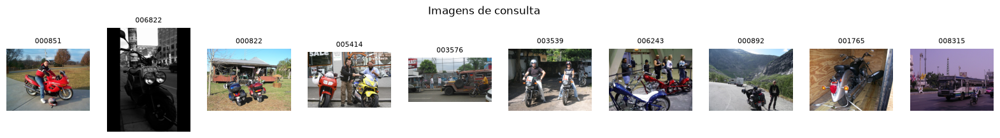

In [33]:
RETRIEVAL_CATEGORY = "motorbike"
N_QUERIES = 10


def load_all(encoding, subset):
    # Todas as imagens de um subset (categorias + background), sem duplicados
    xs, names = [], []
    for category in categories + ["background"]:
        data = np.load(f"data/encodings/{encoding}/{category}_{subset}.npz")
        xs.append(data["histograms"])
        names.extend(data["file_names"])
    x = np.concatenate(xs).astype(np.float32)
    names = np.array(names)

    _, first = np.unique(names, return_index=True)   # 1.ª ocorrência de cada nome
    keep = np.sort(first)                             # mantém a ordem original
    return x[keep], names[keep]


def category_names(category, subset):
    return np.load(f"data/encodings/bovw_K512_C0/{category}_{subset}.npz")["file_names"]


# Consultas: imagens da categoria-alvo no treino
rng = np.random.default_rng(SEED)
query_pool = np.sort(category_names(RETRIEVAL_CATEGORY, "train"))
query_names = rng.choice(query_pool, size=N_QUERIES, replace=False)

_, corpus_names = load_all("bovw_K512_C0", "val")
relevant = np.isin(corpus_names, category_names(RETRIEVAL_CATEGORY, "val"))
assert not np.isin(query_names, corpus_names).any(), "uma consulta está no corpus"

print(f"Corpus: {len(corpus_names)} imagens, {relevant.sum()} relevantes ({relevant.mean():.1%})")

fig, axes = plt.subplots(1, N_QUERIES, figsize=(2 * N_QUERIES, 2.4))
for ax, name in zip(axes, query_names):
    ax.imshow(Image.open(f"data/images/{name}.jpg"))
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.suptitle("Imagens de consulta")
plt.savefig("parte5_consultas.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
def evaluate_retrieval(encoding, representation="tiling", use_sqrt=True, pca_dim=0):
    corpus_x, names = load_all(encoding, "val")
    train_x, train_names = load_all(encoding, "train")
    assert np.array_equal(names, corpus_names), "ordem do corpus diferente entre encodings"

    row_of = {name: i for i, name in enumerate(train_names)}
    query_x = train_x[[row_of[name] for name in query_names]]

    corpus_x = prepare(corpus_x, representation, use_sqrt)
    query_x = prepare(query_x, representation, use_sqrt)

    pca_time = 0.0
    if pca_dim:
        pca = PCA(n_components=pca_dim, random_state=SEED)
        start = time.perf_counter()
        pca.fit(prepare(train_x, representation, use_sqrt))   # só imagens de treino, sem labels
        pca_time = time.perf_counter() - start
        corpus_x = l2norm(pca.transform(corpus_x))
        query_x = l2norm(pca.transform(query_x))

    # Ranking: produto interno = cosseno, porque todos os vetores têm norma 1
    start = time.perf_counter()
    scores = query_x @ corpus_x.T
    rankings = np.argsort(-scores, axis=1)
    query_ms = (time.perf_counter() - start) * 1000 / len(query_x)

    rows = []
    for i, name in enumerate(query_names):
        hits = relevant[rankings[i]]          # True/False ao longo do ranking
        row = {"consulta": name, "AP": average_precision_score(relevant, scores[i])}
        for k in (5, 10, 20):
            row[f"P@{k}"] = hits[:k].mean()
        for k in (20, 100):
            row[f"R@{k}"] = hits[:k].sum() / relevant.sum()
        rows.append(row)

    costs = {"dim": corpus_x.shape[1], "PCA fit (s)": pca_time,
             "ranking (ms/consulta)": query_ms, "corpus (MB)": corpus_x.nbytes / 1e6}
    return pd.DataFrame(rows), rankings, costs


# (nome, encoding, representação, usar raiz, dimensão PCA)
methods = [
    ("BoVW K=512, L2 (sem raiz)",    "bovw_K512_C0",  "tiling", False, 0),
    ("BoVW K=256",                   "bovw_K256_C0",  "tiling", True,  0),
    ("BoVW K=512",                   "bovw_K512_C0",  "tiling", True,  0),
    ("BoVW K=1024",                  "bovw_K1024_C0", "tiling", True,  0),
    ("BoVW K=512 global",            "bovw_K512_C0",  "global", True,  0),
    ("BoVW K=1024 + PCA 256",        "bovw_K1024_C0", "tiling", True,  256),
    ("BoVW K=1024 + PCA 128",        "bovw_K1024_C0", "tiling", True,  128),
    ("VLAD",                         "vlad_K32_C80",  "tiling", True,  0),
    ("VLAD + PCA 256",               "vlad_K32_C80",  "tiling", True,  256),
    ("VLAD + PCA 128",               "vlad_K32_C80",  "tiling", True,  128),
    ("FV",                           "fv_K32_C80",    "tiling", True,  0),
    ("FV + PCA 256",                 "fv_K32_C80",    "tiling", True,  256),
    ("FV + PCA 128",                 "fv_K32_C80",    "tiling", True,  128),
]

per_query, rankings_by_method, summary_rows = {}, {}, []
for name, encoding, representation, use_sqrt, pca_dim in methods:
    if not encoding_exists(encoding):
        print(f"{name}: encodings em falta, a saltar.")
        continue
    table, rankings, costs = evaluate_retrieval(encoding, representation, use_sqrt, pca_dim)
    per_query[name] = table
    rankings_by_method[name] = rankings
    row = {"método": name, "mAP": table["AP"].mean(), "AP desvio": table["AP"].std()}
    for metric in ["P@5", "P@10", "P@20", "R@20", "R@100"]:
        row[metric] = table[metric].mean()
    row.update(costs)
    summary_rows.append(row)

part5 = pd.DataFrame(summary_rows).set_index("método")
part5.round(3)

,mAP,AP desvio,P@5,P@10,P@20,R@20,R@100,dim,PCA fit (s),ranking (ms/consulta),corpus (MB)
método,,,,,,,,,,,
"BoVW K=512, L2 (sem raiz)",0.084,0.045,0.14,0.14,0.145,0.023,0.083,2048,0.000,2.963,18.137
BoVW K=256,0.124,0.054,0.28,0.26,0.215,0.034,0.127,1024,0.000,0.797,9.069
BoVW K=512,0.125,0.055,0.30,0.23,0.220,0.035,0.133,2048,0.000,3.674,18.137
BoVW K=1024,0.129,0.057,0.32,0.23,0.215,0.034,0.134,4096,0.000,3.907,36.274
BoVW K=512 global,0.109,0.043,0.20,0.17,0.165,0.026,0.108,512,0.000,0.463,4.534
BoVW K=1024 + PCA 256,0.119,0.056,0.18,0.19,0.175,0.028,0.113,256,1.384,0.158,2.267
BoVW K=1024 + PCA 128,0.119,0.056,0.20,0.19,0.175,0.028,0.117,128,0.977,0.107,1.134
VLAD,0.101,0.030,0.14,0.17,0.155,0.025,0.099,10240,0.000,8.370,90.685
VLAD + PCA 256,0.103,0.036,0.16,0.15,0.185,0.030,0.099,256,2.066,0.122,2.267


In [35]:
ap_by_query = pd.DataFrame({name: table.set_index("consulta")["AP"] for name, table in per_query.items()})
ap_by_query.round(3)

,"BoVW K=512, L2 (sem raiz)",BoVW K=256,BoVW K=512,BoVW K=1024,BoVW K=512 global,BoVW K=1024 + PCA 256,BoVW K=1024 + PCA 128,VLAD,VLAD + PCA 256,VLAD + PCA 128,FV,FV + PCA 256,FV + PCA 128
consulta,,,,,,,,,,,,,
000851,0.062,0.217,0.220,0.225,0.155,0.210,0.212,0.152,0.158,0.166,0.085,0.194,0.212
006822,0.044,0.044,0.044,0.044,0.041,0.042,0.042,0.061,0.061,0.060,0.043,0.048,0.048
000822,0.044,0.102,0.104,0.105,0.094,0.083,0.084,0.089,0.089,0.091,0.060,0.086,0.084
005414,0.121,0.120,0.119,0.124,0.098,0.116,0.122,0.096,0.093,0.099,0.105,0.141,0.146
003576,0.129,0.140,0.141,0.145,0.116,0.130,0.130,0.107,0.101,0.098,0.093,0.120,0.113
003539,0.130,0.125,0.127,0.136,0.106,0.130,0.129,0.093,0.093,0.096,0.060,0.101,0.104
006243,0.059,0.124,0.128,0.140,0.108,0.172,0.167,0.143,0.159,0.161,0.070,0.166,0.169
000892,0.050,0.133,0.129,0.125,0.160,0.094,0.094,0.087,0.086,0.087,0.048,0.070,0.072
001765,0.158,0.191,0.192,0.198,0.168,0.175,0.173,0.121,0.134,0.136,0.108,0.135,0.134


**Exemplos de rankings**: 

Melhor método: BoVW K=1024


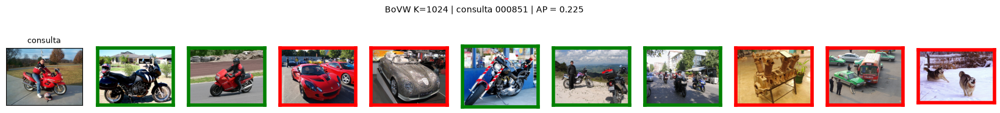

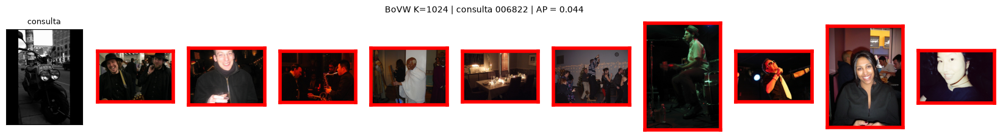

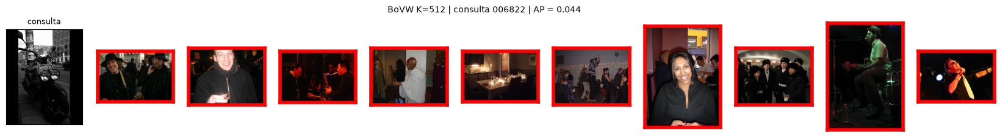

In [36]:
def show_ranking(method, query_name, k=10, file_name=None):
    i = list(query_names).index(query_name)
    top = rankings_by_method[method][i][:k]
    ap = per_query[method].set_index("consulta").loc[query_name, "AP"]

    fig, axes = plt.subplots(1, k + 1, figsize=(1.9 * (k + 1), 2.4))
    axes[0].imshow(Image.open(f"data/images/{query_name}.jpg"))
    axes[0].set_title("consulta", fontsize=9)
    for ax, idx in zip(axes[1:], top):
        ax.imshow(Image.open(f"data/images/{corpus_names[idx]}.jpg"))
        for spine in ax.spines.values():
            spine.set_color("green" if relevant[idx] else "red")
            spine.set_linewidth(4)
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{method} | consulta {query_name} | AP = {ap:.3f}", fontsize=10)
    if file_name:
        plt.savefig(file_name, dpi=150, bbox_inches="tight")
    plt.show()


best_method = part5["mAP"].idxmax()
aps = per_query[best_method].set_index("consulta")["AP"]
print("Melhor método:", best_method)

show_ranking(best_method, aps.idxmax(), file_name="parte5_sucesso.png")
show_ranking(best_method, aps.idxmin(), file_name="parte5_falha.png")

# A mesma consulta difícil com o BoVW, para comparar estratégias
show_ranking("BoVW K=512", aps.idxmin(), file_name="parte5_falha_bovw.png")